# Part 3 · 02 Solution: demand-driven reorder points & safety stock
Deliverables covered:
1. **Relevant features** for defining ROP / safety stock (section 6)
2. **Data science approach** to optimise the levels: rolling demand-driven policy, pattern-specific methods, service levels calibrated by simulation, out-of-sample backtest (sections 1–5)
3. **Recommendation for each article** → `outputs/Part3_ROP_SafetyStock_Recommendations.xlsx` (section 7)

**Setup:** train = 22.01.2019–21.01.2021 (policy parameters, calibration on 2020) · test = 22.01.2021–21.01.2022 (out-of-sample).
Run `01_eda.ipynb` first (it writes `outputs/eda_article_features.parquet`).

In [1]:
import sys, json, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.prep import load_transactions, sbc_class, daily_inventory, END
from src.sim import simulate, optimise_rop
from src.policy import GRID, rop_table, peak_threshold
from src.report import write_workbook
pd.set_option('display.float_format', '{:,.3f}'.format); pd.set_option('display.width', 200)
BLUE, ORANGE, AQUA, YELLOW, GREY, RED = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#8a8985', '#e34948'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e5e0', 'grid.linewidth': .6, 'axes.edgecolor': '#b5b4ad', 'font.size': 10, 'axes.titleweight': 'bold'})
FIG = '../outputs/figures'; save = lambda n: plt.savefig(f'{FIG}/{n}.png', bbox_inches='tight')
tx = load_transactions()
ia = pd.read_parquet('../outputs/eda_article_features.parquet')     # from 01_eda
S0, CUT = pd.Timestamp('2019-01-21'), pd.Timestamp('2021-01-21')
days = pd.date_range(S0 + pd.Timedelta(days=1), END)
TS, T = days.get_loc(CUT + pd.Timedelta(days=1)), len(days)
n = len(ia); price = ia.last_direct_cost.values; LT = ia.lead_time.values; LTs = np.maximum(LT, 1)
print(f'{n} inventory articles | {T} days | test starts at day {TS}')

1751 inventory articles | 1096 days | test starts at day 731


## 1 · Daily demand and 'searched demand' peaks

In [2]:
d = tx[tx.article_nr.isin(ia.index) & tx.is_demand & (tx.date > S0)]
D0 = (d.groupby(['article_nr', 'date']).demand.sum().clip(lower=0).unstack(fill_value=0)
        .reindex(index=ia.index, columns=days, fill_value=0).values)
thr = peak_threshold(D0[:, :TS])                 # learned on train only
D = np.minimum(D0, thr[:, None])                 # base demand served from stock
first = np.where((D > 0).any(1), (D > 0).argmax(1), T)
pk = D0 > thr[:, None]
print(f'Peak days: {100*pk[D0>0].mean():.1f}% of demand days carry {100*(D0*pk)[:, TS:].sum()/D0[:, TS:].sum():.0f}% of test-year volume; '
      f'the part above the threshold (procured to order) is {100*(D0-D)[:, TS:].sum()/D0[:, TS:].sum():.0f}%')

Peak days: 5.0% of demand days carry 29% of test-year volume; the part above the threshold (procured to order) is 14%


Peaks = days where an article's demand exceeds Q3 + 3·IQR of its normal demand days (the case's *searched demand*, e.g. slide 8's 225k spike).
About 5% of demand days carry ~29% of the volume (~14% is the excess above the threshold). Holding safety stock for them would be very expensive; they are planned via customer/production orders
(**procure to order**). The ROP covers the repeatable base demand. Stress test in section 5 shows what happens if peaks were served from stock.

## 2 · Policy inputs at the cut-off date (train data only)

In [3]:
tr12 = D[:, TS-365:TS]
A = pd.DataFrame(index=ia.index)
A['rop_current'] = ia.safety_stock.values.astype(float)
A['usage12'] = tr12.sum(1)
uv = pd.Series(A.usage12.values * price, index=A.index); s = uv.sort_values(ascending=False); c = s.cumsum() / s.sum()
A['ABC'] = pd.Series(np.select([c <= .8, c <= .95], ['A', 'B'], 'C'), index=s.index); A.loc[uv == 0, 'ABC'] = 'C'
mo = D[:, TS % 30:TS].reshape(n, -1, 30).sum(2)
A['demand_class'] = sbc_class(pd.DataFrame(mo, index=A.index)).demand_class.values
# order size = company's typical replenishment (median receipt, 2y) -> isolates the ROP effect
rc = tx[tx.article_nr.isin(ia.index) & tx.entry_type.isin([0, 6]) & (tx.quantity > 0) & (tx.date > S0) & (tx.date <= CUT)]
qh = rc.groupby('article_nr').quantity.median().reindex(A.index).values
q_rule = np.maximum.reduce([ia.moq.values, tr12.mean(1) * 30, np.full(n, 1.1107)])
A['Q'] = np.where(np.isnan(qh), q_rule, np.maximum(qh, ia.moq.values))
# baselines
A['rop_div4'] = A.usage12 / 4
sd_m = D[:, TS % 30:TS].reshape(n, -1, 30).sum(2).std(1)
A['rop_slide11'] = A.usage12 / 360 * LT + sd_m
TARGET = {'A': .98, 'B': .95, 'C': .90}
print(A.ABC.value_counts().to_dict(), '| median typical order = %.1f months of demand' % np.nanmedian(A.Q / (tr12.mean(1) * 30).clip(1e-9)))

{'C': 1311, 'B': 273, 'A': 167} | median typical order = 10.1 months of demand


## 3 · Optimisation: calibrate the service parameter by simulation
The policy (see `src/policy.py`) is recomputed **every month on the last 365 days** of base demand:
- smooth / erratic demand → `ROP = μ·LT + z(p)·σ_week·√(LT/7)`
- intermittent / lumpy / sporadic → `ROP = p-quantile of historical lead-time demand` (non-parametric, robust to lumpiness)
- no demand → ROP 0 · no lead time maintained → company fallback (usage / 4)

`p` is not guessed: for each ABC class we simulate 2020 with every p in the grid and pick the **smallest p that reaches the class fill-rate target**
(A 98%, B 95%, C 90%) → least capital for the required service.

In [4]:
dc = A.demand_class.values; Q = A.Q.values; rows = np.arange(n)
reb = list(range(TS - 365 - 90, T, 30))
tabs = {t: rop_table(D, t, LT, dc, first=first)[0] for t in reb}
def rop_matrix(p_idx):
    R = np.zeros(D.shape)
    for t in reb: R[:, t:min(t + 30, T)] = tabs[t][rows, p_idx][:, None]
    return R
def kpi(r, name, **kw):
    v = r['avg_onhand'] * price; dv = r['demand'] * price
    out = dict(policy=name, lockup=v.sum(), fill=(r['fill_rate'] * dv).sum() / dv.sum())
    for c_ in 'ABC':
        m = (A.ABC == c_).values; out['fill_' + c_] = (r['fill_rate'][m] * dv[m]).sum() / dv[m].sum()
    out['stockout_articles'] = int((r['stockout_days'] > 0).sum()); out['orders'] = int(r['orders'].sum()); out.update(kw)
    return out
cal = []
for g in range(len(GRID)):
    r = simulate(D, rop_matrix(np.full(n, g)), Q, LTs, TS - 365, TS)
    dv = r['demand'] * price
    for c_ in 'ABC':
        m = (A.ABC == c_).values
        cal.append(dict(p=GRID[g], cls=c_, fill=(r['fill_rate'][m] * dv[m]).sum() / dv[m].sum()))
cal = pd.DataFrame(cal).pivot(index='p', columns='cls', values='fill')
p_cls = {c_: float(cal.index[cal[c_] >= TARGET[c_]].min()) if (cal[c_] >= TARGET[c_]).any() else float(GRID.max()) for c_ in 'ABC'}
p_idx = A.ABC.map(lambda c_: int(np.where(GRID == p_cls[c_])[0][0])).values
print('Calibrated service parameter:', p_cls); cal.iloc[::3]

Calibrated service parameter: {'A': 0.995, 'B': 0.995, 'C': 0.85}


cls,A,B,C
p,,,
0.500,0.698,0.742,0.808
0.650,0.764,0.789,0.839
0.800,0.818,0.839,0.882
0.950,0.882,0.916,0.949
0.965,0.890,0.924,0.957
0.980,0.902,0.934,0.962
0.995,0.920,0.944,0.967


A- and B-articles cap at p = 99.5% (target not fully reachable on 2020: new articles ramping up and long lead times; see notes per article).

## 4 · Out-of-sample backtest 2021: does it beat today's policy?

In [5]:
res, K = {}, []
for m, lab in [('rop_current', 'Current ROP (master data)'), ('rop_div4', 'Rule: usage 12m / 4'), ('rop_slide11', 'Slide-11 formula')]:
    res[m] = simulate(D, A[m].values, Q, LTs, TS, T); K.append(kpi(res[m], lab))
static = rop_table(D, TS, LT, dc, first=first)[0][rows, p_idx]
res['static'] = simulate(D, static, Q, LTs, TS, T); K.append(kpi(res['static'], 'Demand-driven, static (set once)'))
res['dynamic'] = simulate(D, rop_matrix(p_idx), Q, LTs, TS, T); K.append(kpi(res['dynamic'], 'Demand-driven, monthly update (recommended)'))
K = pd.DataFrame(K).set_index('policy')
F = pd.DataFrame([kpi(simulate(D, rop_matrix(np.full(n, g)), Q, LTs, TS, T), 'frontier', p=GRID[g]) for g in range(len(GRID))])
eod = daily_inventory(tx, ia.index, start=str(S0.date())).reindex(columns=ia.index)
actual_val = eod.loc[days[TS]:].fillna(0).mean().values * price
print(f'Actual 2021 avg stock value (observed): {actual_val.sum():,.0f}'); K

Actual 2021 avg stock value (observed): 4,924,745


,lockup,fill,fill_A,fill_B,fill_C,stockout_articles,orders
policy,,,,,,,
Current ROP (master data),"2,793,487.475",0.711,0.677,0.800,0.844,539,4921
Rule: usage 12m / 4,"3,078,099.626",0.833,0.827,0.903,0.749,456,4912
Slide-11 formula,"2,433,797.886",0.847,0.859,0.854,0.736,698,4920
"Demand-driven, static (set once)","3,441,391.618",0.931,0.956,0.936,0.709,623,4924
"Demand-driven, monthly update (recommended)","3,652,473.422",0.951,0.973,0.952,0.759,602,5092


Current ROP (master data)    fill 71.1% at   2,793,487 | demand-driven at same fill:   1,843,975 (-34%)
Rule: usage 12m / 4          fill 83.3% at   3,078,100 | demand-driven at same fill:   2,366,137 (-23%)
Slide-11 formula             fill 84.7% at   2,433,798 | demand-driven at same fill:   2,460,631 (+1%)


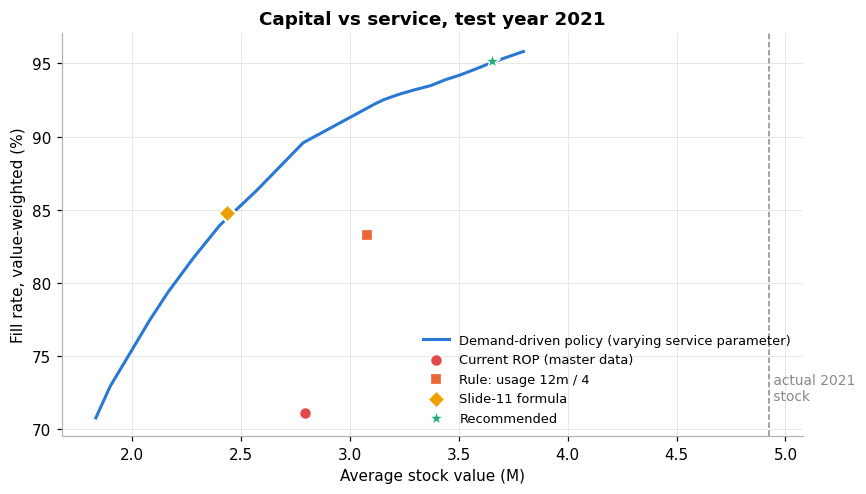

In [6]:
for lab in K.index[:3]:
    f = K.loc[lab, 'fill']; lk = np.interp(f, F.fill, F.lockup)
    print(f'{lab:28s} fill {f:.1%} at {K.loc[lab,"lockup"]:>11,.0f} | demand-driven at same fill: {lk:>11,.0f} ({lk/K.loc[lab,"lockup"]-1:+.0%})')
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(F.lockup / 1e6, F.fill * 100, color=BLUE, lw=2, label='Demand-driven policy (varying service parameter)')
for lab, col, mk in [('Current ROP (master data)', RED, 'o'), ('Rule: usage 12m / 4', ORANGE, 's'), ('Slide-11 formula', YELLOW, 'D')]:
    ax.scatter(K.loc[lab, 'lockup'] / 1e6, K.loc[lab, 'fill'] * 100, color=col, s=70, marker=mk, zorder=3, label=lab, edgecolor='white', lw=1.5)
rec = K.loc['Demand-driven, monthly update (recommended)']
ax.scatter(rec.lockup / 1e6, rec.fill * 100, color=AQUA, s=110, marker='*', zorder=3, label='Recommended', edgecolor='white', lw=1)
ax.axvline(actual_val.sum() / 1e6, color=GREY, ls='--', lw=1); ax.text(actual_val.sum() / 1e6, 72, ' actual 2021\n stock', color=GREY, fontsize=9)
ax.set_xlabel('Average stock value (M)'); ax.set_ylabel('Fill rate, value-weighted (%)')
ax.set_title('Capital vs service, test year 2021'); ax.legend(frameon=False, fontsize=8.5, loc='lower right')
plt.tight_layout(); save('06_tradeoff_curve'); plt.show()

**Read:**
- **Efficiency:** for the *same* fill rate, the demand-driven policy needs **~34% less capital than today's ROPs** and ~23% less than the ÷4 rule. The slide-11 formula sits near the curve, but it has no service lever, protects C-articles poorly, and its σ is distorted by peaks.
- **Today's ROPs alone give only ~71% fill (A-articles ~68%).** That explains why planners top up by hand and why actual stock was 4.9M.
- **Recommended setting:** ~95% fill (A ~97%) with ~3.65M average stock, about **1.27M (−26%) less than actual 2021** and with ROPs that can be trusted, so no manual buffering is needed.
- Monthly updating beats setting the levels once (+2pp fill). That is the *demand-driven* part.

## 5 · Stress tests

In [7]:
Rm = rop_matrix(p_idx); D0full = D0
mu_cut = rop_table(D, TS, LT, dc, first=first)[1]
S = pd.DataFrame([kpi(simulate(D, Rm, Q, LTs, TS, T), 'Recommended (base case)'),
    kpi(simulate(D, Rm, np.maximum.reduce([ia.moq.values, mu_cut*60, np.full(n, 1.1107)]), LTs, TS, T), '+ order qty right-sized: max(MOQ, 2 months demand)'),
    kpi(simulate(D, Rm, Q, np.ceil(LTs*1.5).astype(int), TS, T), 'Stress: actual lead time +50%'),
    kpi(simulate(D0full, Rm, Q, LTs, TS, T), 'Stress: peaks served from stock (not to order)')]).set_index('policy'); S

,lockup,fill,fill_A,fill_B,fill_C,stockout_articles,orders
policy,,,,,,,
Recommended (base case),"3,652,473.422",0.951,0.973,0.952,0.759,602,5092
"+ order qty right-sized: max(MOQ, 2 months demand)","3,629,445.264",0.946,0.972,0.952,0.713,715,5338
Stress: actual lead time +50%,"3,150,492.737",0.869,0.879,0.903,0.711,735,5092
Stress: peaks served from stock (not to order),"3,551,189.079",0.850,0.862,0.871,0.701,710,5453


- **Lead time matters most:** if real lead times were 50% longer than the master data, fill would fall to ~87%. Lead times are manual, round numbers, so maintaining *measured* lead times is a key recommendation.
- **Peaks must be planned:** serving one-off peaks from stock drops fill to ~85%. Searched demand needs order-driven planning, not a bigger buffer.
- Shrinking order sizes to 2 months of demand changes little in this simulation, so the ROP is the lever here.

## 6 · Which features drive the right ROP / safety stock?

In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import mutual_info_regression
from scipy.stats import spearmanr
cs_ = lambda w: np.r_[0, w.cumsum()]
ltd_max = np.array([(cs_(D[i, :TS])[L:] - cs_(D[i, :TS])[:-L]).max() for i, L in enumerate(LTs)])
ropt, _ = optimise_rop(D[:, :TS], Q, LTs, 0.95, start=180, end=TS, hi=np.maximum(ltd_max * 1.2, 1e-6))   # ground truth
tr = D[:, :TS]; mu = tr[:, -365:].mean(1); wk = tr[:, TS % 7:].reshape(n, -1, 7).sum(2)
X = pd.DataFrame(index=A.index)
X['mean_daily_demand (log)'] = np.log1p(mu)
X['CV weekly demand'] = wk.std(1) / np.where(wk.mean(1) > 0, wk.mean(1), np.nan)
X['ADI (demand interval)'] = ia.ADI.values; X['CV² demand size'] = ia.CV2.values
X['lead_time (days)'] = LT
X['order qty in days of demand (log)'] = np.log1p(Q / np.where(mu > 0, mu, np.nan))
X['MOQ maintained'] = (ia.moq > 0).astype(int).values
X['purchase price (log)'] = np.log1p(price)
X['usage value 12m (log)'] = np.log1p(tr[:, -365:].sum(1) * price)
X['peak share of volume'] = 1 - tr.sum(1) / np.where(D0[:, :TS].sum(1) > 0, D0[:, :TS].sum(1), np.nan)
X['trend (last 6m / prior 6m)'] = np.log1p(tr[:, -182:].sum(1)) - np.log1p(tr[:, -365:-182].sum(1))
X['days since first demand'] = TS - first
X['eshop'] = ia.eshop.astype(int).values
X['type: Semi-finished'] = (ia.ptype == 'Semi-finished / component').astype(int).values
X['type: Finished'] = (ia.ptype == 'Finished (produced in-house)').astype(int).values
X['ABC = A'] = (A.ABC == 'A').astype(int).values
y = np.log1p(ropt / np.where(mu > 0, mu, np.nan))          # required ROP in days of demand
m = (mu > 0) & (LT > 0) & np.isfinite(y); Xm = X[m].fillna(X[m].median()); ym = y[m]
rf = RandomForestRegressor(400, min_samples_leaf=5, random_state=0, n_jobs=-1)
r2 = cross_val_score(rf, Xm, ym, cv=KFold(5, shuffle=True, random_state=0), scoring='r2')
rf.fit(Xm, ym); pi = permutation_importance(rf, Xm, ym, n_repeats=10, random_state=0, n_jobs=-1)
FI = pd.DataFrame({'permutation_importance': pi.importances_mean, 'mutual_information': mutual_info_regression(Xm, ym, random_state=0),
                   'spearman_rho': [spearmanr(Xm[c_], ym).correlation for c_ in Xm]}, index=Xm.columns).sort_values('permutation_importance', ascending=False)
print(f'{m.sum()} articles | random forest 5-fold CV R² = {r2.mean():.2f}'); FI

1279 articles | random forest 5-fold CV R² = 0.61


,permutation_importance,mutual_information,spearman_rho
order qty in days of demand (log),1.365,0.461,-0.559
CV weekly demand,0.166,0.365,0.045
lead_time (days),0.106,0.149,0.253
trend (last 6m / prior 6m),0.058,0.224,-0.022
days since first demand,0.050,0.217,0.016
usage value 12m (log),0.045,0.205,0.306
purchase price (log),0.024,0.103,0.184
CV² demand size,0.023,0.117,0.092
mean_daily_demand (log),0.023,0.242,0.076
ADI (demand interval),0.015,0.386,0.042


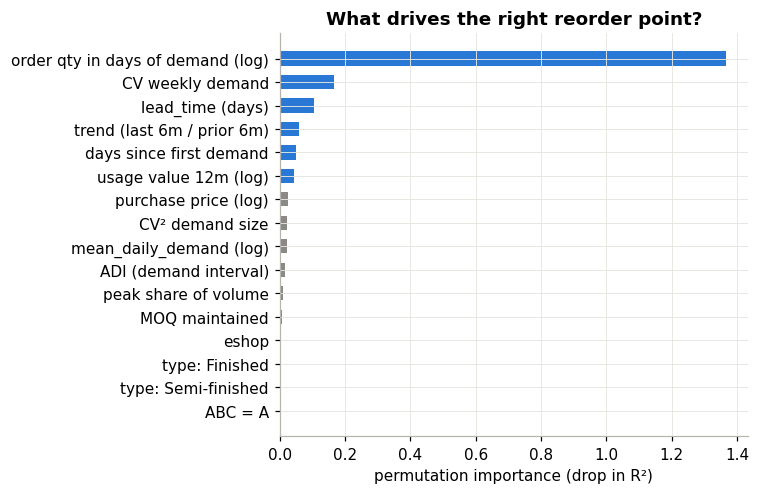

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.6))
f_ = FI.permutation_importance.iloc[::-1]
ax.barh(f_.index, f_.values, color=[BLUE if v > .04 else GREY for v in f_.values], height=.6)
ax.set_title('What drives the right reorder point?'); ax.set_xlabel('permutation importance (drop in R²)')
plt.tight_layout(); save('07_feature_importance'); plt.show()

**Target:** for each article, the *simulation-optimal* ROP: the smallest ROP that reaches 95% fill on the training years, expressed in days of demand.
**Relevant features (ranked):**
1. **Order quantity in days of demand.** This is by far the strongest. Large orders leave a big cycle stock that already buffers demand, so less ROP is needed (ρ = −0.56). ROP and order size must be set together.
2. **Demand variability (CV of weekly demand)**: the classic safety stock driver.
3. **Lead time**: longer exposure needs a higher ROP (ρ = +0.25).
4. **Trend and article age**: growing or new articles need a forward-looking ROP, hence the monthly update.
5. **Value (usage value, price)**: matters through the service target (ABC).

Product type, e-shop and the ABC flag itself add almost nothing once these are known. They are useful for *policy* (service targets), not for the *level*.
This is why the solution uses μ, σ, LT, order size and demand pattern directly.

## 7 · Recommendation for each article (as of 21.01.2022)

In [10]:
thr_l = peak_threshold(D0[:, T-730:]); Dl = np.minimum(D0, thr_l[:, None])
first_l = np.where((Dl > 0).any(1), (Dl > 0).argmax(1), T)
dc_l = sbc_class(pd.DataFrame(Dl[:, T-720:].reshape(n, -1, 30).sum(2), index=A.index)).demand_class.values
u12 = Dl[:, T-365:].sum(1) * price; s = pd.Series(u12, index=A.index).sort_values(ascending=False); c = s.cumsum() / s.sum()
abc = pd.Series(np.select([c <= .8, c <= .95], ['A', 'B'], 'C'), index=s.index).reindex(A.index); abc[u12 == 0] = 'C'
p = abc.map(p_cls).values; pi_ = np.array([np.where(GRID == x)[0][0] for x in p])
tab, mu_l = rop_table(Dl, T, LT, dc_l, first=first_l); rop = tab[rows, pi_]
cur = A.rop_current.values; ratio = rop / np.where(cur > 0, cur, np.nan)
R = pd.DataFrame(index=A.index); R.index.name = 'Article'
R['ABC class'] = abc.values; R['Demand pattern'] = dc_l; R['Product type'] = ia.ptype.values; R['Vendor'] = ia.vendor_nr.astype(str).values
R['Lead time (days)'] = LT; R['MOQ'] = ia.moq.values; R['Typical order qty'] = Q; R['Purchase price'] = price
R['Usage last 12m (units)'] = D0[:, T-365:].sum(1); R['Avg daily base demand'] = mu_l
R['Current ROP'] = cur; R['Recommended ROP'] = rop
R['Recommended safety stock'] = np.where(LT > 0, np.maximum(rop - mu_l * LT, 0), rop)
R['Service parameter'] = p
R['Method'] = np.where(mu_l <= 0, 'ROP = 0 (no demand)', np.where(LT <= 0, 'Fallback: usage 12m / 4',
              np.where(np.isin(dc_l, ['Smooth', 'Erratic']), 'Normal: mu·LT + z·sigma·sqrt(LT)', 'Empirical quantile of lead-time demand')))
R['Procure-to-order above (units/day)'] = np.where(np.isfinite(thr_l), thr_l, np.nan)
R['Action'] = np.select([mu_l <= 0, LT <= 0, ratio < .8, ratio > 1.2],
    ['Set ROP to 0: no demand in 12 months (run down stock, procure to order)', 'Keep fallback rule; maintain lead time in master data',
     'Reduce ROP', 'Increase ROP'], 'Keep (within ±20%)')
ps = 1 - Dl[:, T-365:].sum(1) / np.where(D0[:, T-365:].sum(1) > 0, D0[:, T-365:].sum(1), np.nan)
R['Notes'] = ['; '.join(filter(None, [
    'New article (<12m history): review quarterly' if (T - first_l[i] < 365 and mu_l[i] > 0) else '',
    f'{ps[i]:.0%} of volume is one-off peaks: plan via customer/production orders' if ps[i] > .3 else '',
    'Long lead time: check supplier lead time' if LT[i] >= 60 else ''])) for i in range(n)]
R['Sim. avg stock value - current'] = res['rop_current']['avg_onhand'] * price
R['Sim. avg stock value - recommended'] = res['dynamic']['avg_onhand'] * price
R['Sim. fill rate - current'] = res['rop_current']['fill_rate']; R['Sim. fill rate - recommended'] = res['dynamic']['fill_rate']
R['Actual avg stock value 2021'] = actual_val
write_workbook(R, K, F, FI, S, p_cls, '../outputs/Part3_ROP_SafetyStock_Recommendations.xlsx')
R.Action.value_counts().to_frame('articles')

,articles
Action,
Reduce ROP,794
Increase ROP,459
"Set ROP to 0: no demand in 12 months (run down stock, procure to order)",321
Keep (within ±20%),146
Keep fallback rule; maintain lead time in master data,31


In [11]:
act = R.groupby('Action').agg(articles=('Current ROP', 'size'),
                             stock_current=('Sim. avg stock value - current', 'sum'), stock_recommended=('Sim. avg stock value - recommended', 'sum'),
                             actual_2021=('Actual avg stock value 2021', 'sum'))
act['vs_actual'] = act.stock_recommended - act.actual_2021; display(act.sort_values('articles', ascending=False))
rr = R.groupby('ABC class').agg(articles=('Current ROP', 'size'), actual_2021=('Actual avg stock value 2021', 'sum'),
                                recommended=('Sim. avg stock value - recommended', 'sum'), fill_current=('Sim. fill rate - current', 'median'),
                                fill_recommended=('Sim. fill rate - recommended', 'median')); rr

,articles,stock_current,stock_recommended,actual_2021,vs_actual
Action,,,,,
Reduce ROP,794,"1,244,928.370","795,657.214","1,310,395.053","-514,737.839"
Increase ROP,459,"773,078.668","2,199,429.470","2,674,750.401","-475,320.931"
"Set ROP to 0: no demand in 12 months (run down stock, procure to order)",321,"392,141.347","266,482.933","244,537.492","21,945.440"
Keep (within ±20%),146,"360,562.902","364,611.415","675,123.282","-310,511.867"
Keep fallback rule; maintain lead time in master data,31,"22,776.187","26,292.391","19,938.503","6,353.888"


,articles,actual_2021,recommended,fill_current,fill_recommended
ABC class,,,,,
A,179,"3,298,583.550","2,290,766.754",0.893,1.000
B,302,"725,267.403","622,286.188",0.938,1.000
C,1270,"900,893.778","739,420.479",1.000,1.000


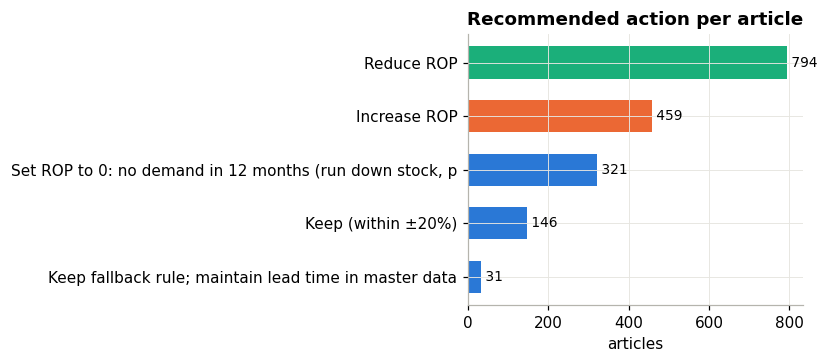

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
a_ = R.Action.value_counts().iloc[::-1]
cols = {'Reduce ROP': AQUA, 'Increase ROP': ORANGE}
ax.barh([t[:55] for t in a_.index], a_.values, color=[cols.get(t, BLUE) for t in a_.index], height=.6)
for i, v in enumerate(a_.values): ax.text(v, i, f' {v}', va='center', fontsize=9)
ax.set_title('Recommended action per article'); ax.set_xlabel('articles')
plt.tight_layout(); save('08_actions'); plt.show()

## 8 · Business case

In [13]:
HOLD = 0.20   # holding cost rate p.a. (assumption: 15–25%)
rec = K.loc['Demand-driven, monthly update (recommended)']
released = actual_val.sum() - rec.lockup
print(f'Actual avg stock value 2021 (observed):        {actual_val.sum():>12,.0f}')
print(f'Recommended policy (simulated):                 {rec.lockup:>12,.0f}')
print(f'Capital released:                               {released:>12,.0f}  ({released/actual_val.sum():.0%})')
print(f'Annual holding-cost saving @ {HOLD:.0%}:              {released*HOLD:>12,.0f}  (15%: {released*.15:,.0f} | 25%: {released*.25:,.0f})')
print(f'Fill rate: {rec.fill:.1%} overall, {rec.fill_A:.1%} on A-articles (current ROPs followed strictly: {K.iloc[0].fill:.1%} / {K.iloc[0].fill_A:.1%})')
cur_ = K.loc['Current ROP (master data)']; same = np.interp(cur_.fill, F.fill, F.lockup)
print(f'At the SAME service as current ROPs: {same:,.0f} vs {cur_.lockup:,.0f} -> {1-same/cur_.lockup:.0%} less capital')

Actual avg stock value 2021 (observed):           4,924,745
Recommended policy (simulated):                    3,652,473
Capital released:                                  1,272,271  (26%)
Annual holding-cost saving @ 20%:                   254,454  (15%: 190,841 | 25%: 318,068)
Fill rate: 95.1% overall, 97.3% on A-articles (current ROPs followed strictly: 71.1% / 67.7%)
At the SAME service as current ROPs: 1,843,975 vs 2,793,487 -> 34% less capital


### Recommendations to the company
1. **Replace manual ROPs with demand-driven ROPs, updated monthly**: about 26% less capital than 2021 at ~95% fill (A ~97%), and 34% less capital at today's service level. One rule set, by demand pattern and ABC class.
2. **Clean up 321 articles with no demand in 12 months**: set ROP to 0, run down the stock, procure to order.
3. **Plan "searched demand" peaks via orders, not stock**: about 29% of volume comes on 5% of demand days. Use the per-article procure-to-order threshold.
4. **Maintain real lead times**: they are manual round numbers, and a 50% error costs about 8pp of fill. Add order and receipt dates to measure lead time variability.
5. **Set ROP and order size together**: order size in days of demand is the strongest driver of the required ROP.
6. **Review new or growing articles quarterly**: the monthly recalculation picks up ramp-ups, but long-lead-time launches need forecast input from production planning.